In [ ]:
import polars as pl
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent        
book = pl.read_parquet(ROOT / "data" / "processed" / "book_states.parquet")
trades = pl.read_parquet(ROOT / "data" / "processed" / "trades.parquet")
print(book.shape, trades.shape)
book.head()

(7451501, 11) (39096, 10)


timestamp,bid_prices,bid_sizes,ask_prices,ask_sizes,ofi,symbol,session,mid,spread,dmid
"datetime[μs, UTC]",f64,i64,f64,i64,i64,str,str,f64,f64,f64
2026-09-11 12:00:01.118533 UTC,762.28,100,null,null,null,"""SPY""","""pre""",null,null,null
2026-09-11 12:00:01.118620 UTC,762.28,100,762.41,100,null,"""SPY""","""pre""",762.345,0.13,null
2026-09-11 12:00:01.369084 UTC,762.31,100,762.41,100,100,"""SPY""","""pre""",762.36,0.1,0.015
2026-09-11 12:00:01.517991 UTC,762.28,100,762.41,100,-100,"""SPY""","""pre""",762.345,0.13,-0.015
2026-09-11 12:00:01.628174 UTC,762.31,100,762.41,100,100,"""SPY""","""pre""",762.36,0.1,0.015


share of exactly zero: 0.2174533560818478
1%, 50%, 99%, 99.9% percentiles: [-200.0, 0.0, 200.0, 485.0]


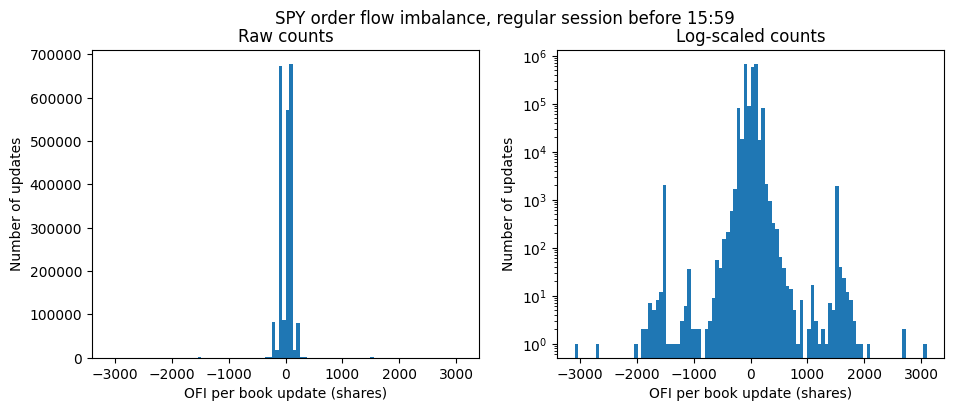

min/max: -3100 3100
rows at exactly ±1500 now: 3910 (was 4,514 with the final minute)
rows at exactly ±1080 now: 51 (was 360 with the final minute)


In [36]:
(ROOT / "figures").mkdir(exist_ok=True)

ny = pl.col("timestamp").dt.convert_time_zone("America/New_York")
spy = (book.filter((pl.col("symbol") == "SPY") & (pl.col("session") == "regular"))
           .filter((ny.dt.hour() < 15) | ((ny.dt.hour() == 15) & (ny.dt.minute() < 59)))
           .drop_nulls("ofi"))
ofi = spy["ofi"].to_numpy()
print("share of exactly zero:", (ofi == 0).mean())
print("1%, 50%, 99%, 99.9% percentiles:", [float(x) for x in
      __import__("numpy").percentile(ofi, [1, 50, 99, 99.9])])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(ofi, bins=100)
ax[0].set_title("Raw counts")
ax[1].hist(ofi, bins=100)
ax[1].set_yscale("log")
ax[1].set_title("Log-scaled counts")
for a in ax:
    a.set_xlabel("OFI per book update (shares)")
    a.set_ylabel("Number of updates")
fig.suptitle("SPY order flow imbalance, regular session before 15:59")
fig.savefig(ROOT / "figures" / "01_spy_ofi_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print("min/max:", ofi.min(), ofi.max())
print("rows at exactly ±1500 now:", spy.filter(pl.col("ofi").abs() == 1500).height, "(was 4,514 with the final minute)")
print("rows at exactly ±1080 now:", spy.filter(pl.col("ofi").abs() == 1080).height, "(was 360 with the final minute)")

windows: 23340 | rank corr: 0.5919579131734685
OFI  min/max: -31568 12606 | plot edges: -3896.525 3736.100000000006
dmid min/max: -0.7800000000000864 11.80499999999995 | plot edges: -0.24652500000000313 0.2599999999999909
share outside plot box: 0.01979434447300771


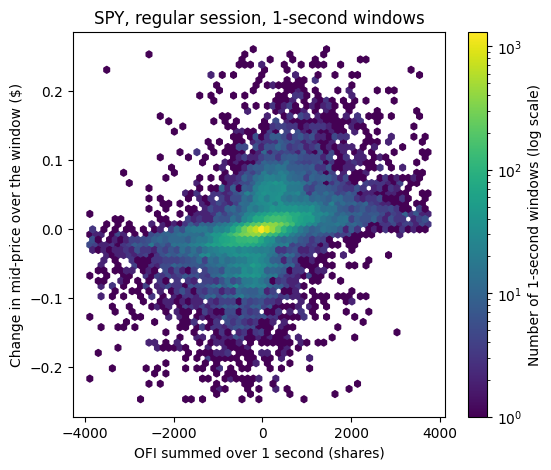

In [5]:
import numpy as np

w = (book.filter((pl.col("symbol") == "SPY") & (pl.col("session") == "regular"))
         .sort("timestamp")
         .group_by_dynamic("timestamp", every="1s")
         .agg(pl.col("ofi").sum().alias("ofi_sum"), pl.col("mid").last().alias("mid_end"))
         .with_columns(pl.col("mid_end").diff().alias("dmid_w"))
         .drop_nulls(["ofi_sum", "dmid_w"]))

x, y = w["ofi_sum"].to_numpy(), w["dmid_w"].to_numpy()
print("windows:", len(w), "| rank corr:", w.select(pl.corr("ofi_sum", "dmid_w", method="spearman")).item())

lx, hx = np.percentile(x, [0.5, 99.5]); ly, hy = np.percentile(y, [0.5, 99.5])
print("OFI  min/max:", x.min(), x.max(), "| plot edges:", lx, hx)
print("dmid min/max:", y.min(), y.max(), "| plot edges:", ly, hy)
print("share outside plot box:", ((x < lx) | (x > hx) | (y < ly) | (y > hy)).mean())
fig, ax = plt.subplots(figsize=(6, 5))
hb = ax.hexbin(x, y, gridsize=60, bins="log", extent=(lx, hx, ly, hy), mincnt=1)
fig.colorbar(hb, label="Number of 1-second windows (log scale)")
ax.set_xlabel("OFI summed over 1 second (shares)")
ax.set_ylabel("Change in mid-price over the window ($)")
ax.set_title("SPY, regular session, 1-second windows")
fig.savefig(ROOT / "figures" / "02_spy_ofi_vs_dmid_1s.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
from scipy.stats import theilslopes

rng = np.random.default_rng(42)
idx = rng.choice(len(x), size=5000, replace=False)

slope, intercept, lo, hi = theilslopes(y[idx], x[idx])
print("slope:", slope, "| 95% range:", lo, hi)
print("intercept:", intercept)
print("per 1,000 shares of OFI: $", slope * 1000)

slope: 2.0779220779260937e-05 | 95% range: 1.9823788546337642e-05 2.1739130434762837e-05
intercept: 0.00010389610389630468
per 1,000 shares of OFI: $ 0.020779220779260938


In [8]:
pl.Config.set_tbl_cols(10)

i_big = int(w["dmid_w"].arg_max())
print("Largest mid-price jump, with 2 rows before and after:")
print(w.slice(max(i_big - 2, 0), 5))

i_low = int(w["ofi_sum"].arg_min())
print("\nMost negative OFI, with 2 rows before and after:")
print(w.slice(max(i_low - 2, 0), 5))

Largest mid-price jump, with 2 rows before and after:
shape: (3, 4)
┌─────────────────────────┬─────────┬─────────┬────────┐
│ timestamp               ┆ ofi_sum ┆ mid_end ┆ dmid_w │
│ ---                     ┆ ---     ┆ ---     ┆ ---    │
│ datetime[μs, UTC]       ┆ i64     ┆ f64     ┆ f64    │
╞═════════════════════════╪═════════╪═════════╪════════╡
│ 2026-09-11 19:59:57 UTC ┆ -31568  ┆ 764.105 ┆ -0.105 │
│ 2026-09-11 19:59:58 UTC ┆ -13878  ┆ 764.14  ┆ 0.035  │
│ 2026-09-11 19:59:59 UTC ┆ 2263    ┆ 775.945 ┆ 11.805 │
└─────────────────────────┴─────────┴─────────┴────────┘

Most negative OFI, with 2 rows before and after:
shape: (5, 4)
┌─────────────────────────┬─────────┬─────────┬────────┐
│ timestamp               ┆ ofi_sum ┆ mid_end ┆ dmid_w │
│ ---                     ┆ ---     ┆ ---     ┆ ---    │
│ datetime[μs, UTC]       ┆ i64     ┆ f64     ┆ f64    │
╞═════════════════════════╪═════════╪═════════╪════════╡
│ 2026-09-11 19:59:55 UTC ┆ -4303   ┆ 764.325 ┆ 0.0    │
│ 2026-09-11 

In [9]:
from datetime import timedelta

t = w["timestamp"][i_big]
raw = (book.filter((pl.col("symbol") == "SPY")
                   & (pl.col("timestamp") >= t)
                   & (pl.col("timestamp") < t + timedelta(seconds=1)))
           .select("timestamp", "ofi", "mid", "spread"))
print(len(raw), "book states in that second")
print(raw.head(30))

767 book states in that second
shape: (30, 4)
┌────────────────────────────────┬──────┬─────────┬────────┐
│ timestamp                      ┆ ofi  ┆ mid     ┆ spread │
│ ---                            ┆ ---  ┆ ---     ┆ ---    │
│ datetime[μs, UTC]              ┆ i64  ┆ f64     ┆ f64    │
╞════════════════════════════════╪══════╪═════════╪════════╡
│ 2026-09-11 19:59:59.004994 UTC ┆ 65   ┆ 764.145 ┆ 0.03   │
│ 2026-09-11 19:59:59.005016 UTC ┆ 0    ┆ 764.145 ┆ 0.03   │
│ 2026-09-11 19:59:59.005246 UTC ┆ 100  ┆ 764.145 ┆ 0.03   │
│ 2026-09-11 19:59:59.005311 UTC ┆ -100 ┆ 764.145 ┆ 0.03   │
│ 2026-09-11 19:59:59.005530 UTC ┆ 0    ┆ 764.145 ┆ 0.03   │
│ …                              ┆ …    ┆ …       ┆ …      │
│ 2026-09-11 19:59:59.016957 UTC ┆ 65   ┆ 764.25  ┆ 0.2    │
│ 2026-09-11 19:59:59.017443 UTC ┆ 200  ┆ 764.25  ┆ 0.2    │
│ 2026-09-11 19:59:59.019351 UTC ┆ -200 ┆ 764.25  ┆ 0.2    │
│ 2026-09-11 19:59:59.019790 UTC ┆ 100  ┆ 764.25  ┆ 0.2    │
│ 2026-09-11 19:59:59.019836 UTC ┆ 200 

In [10]:
pl.Config.set_tbl_rows(20)
print(raw.tail(10))
print(raw.select(pl.col("mid").max(), pl.col("spread").max()))
print(raw.filter(pl.col("mid") > 770).head(5))

shape: (10, 4)
┌────────────────────────────────┬───────┬─────────┬────────┐
│ timestamp                      ┆ ofi   ┆ mid     ┆ spread │
│ ---                            ┆ ---   ┆ ---     ┆ ---    │
│ datetime[μs, UTC]              ┆ i64   ┆ f64     ┆ f64    │
╞════════════════════════════════╪═══════╪═════════╪════════╡
│ 2026-09-11 19:59:59.991511 UTC ┆ 100   ┆ 764.185 ┆ 0.03   │
│ 2026-09-11 19:59:59.991645 UTC ┆ 200   ┆ 764.27  ┆ 0.2    │
│ 2026-09-11 19:59:59.991891 UTC ┆ -100  ┆ 764.26  ┆ 0.22   │
│ 2026-09-11 19:59:59.992074 UTC ┆ 1080  ┆ 764.265 ┆ 0.23   │
│ 2026-09-11 19:59:59.993092 UTC ┆ 1080  ┆ 764.27  ┆ 0.24   │
│ 2026-09-11 19:59:59.995128 UTC ┆ -1080 ┆ 764.265 ┆ 0.25   │
│ 2026-09-11 19:59:59.996154 UTC ┆ 1080  ┆ 764.27  ┆ 0.26   │
│ 2026-09-11 19:59:59.997168 UTC ┆ -1080 ┆ 764.265 ┆ 0.27   │
│ 2026-09-11 19:59:59.998188 UTC ┆ 1080  ┆ 775.95  ┆ 23.64  │
│ 2026-09-11 19:59:59.999208 UTC ┆ -1080 ┆ 775.945 ┆ 23.65  │
└────────────────────────────────┴───────┴─────────┴───

In [11]:
w_ny = w.with_columns(pl.col("timestamp").dt.convert_time_zone("America/New_York").alias("ny"))
print(w_ny.sort(pl.col("dmid_w").abs(), descending=True).select("ny", "ofi_sum", "dmid_w").head(10))
print(w_ny.sort(pl.col("ofi_sum").abs(), descending=True).select("ny", "ofi_sum", "dmid_w").head(10))

shape: (10, 3)
┌────────────────────────────────┬─────────┬────────┐
│ ny                             ┆ ofi_sum ┆ dmid_w │
│ ---                            ┆ ---     ┆ ---    │
│ datetime[μs, America/New_York] ┆ i64     ┆ f64    │
╞════════════════════════════════╪═════════╪════════╡
│ 2026-09-11 15:59:59 EDT        ┆ 2263    ┆ 11.805 │
│ 2026-09-11 09:40:36 EDT        ┆ 11043   ┆ 1.115  │
│ 2026-09-11 09:30:56 EDT        ┆ 1305    ┆ 0.8    │
│ 2026-09-11 09:31:45 EDT        ┆ -1575   ┆ -0.78  │
│ 2026-09-11 09:33:45 EDT        ┆ -560    ┆ -0.78  │
│ 2026-09-11 09:30:13 EDT        ┆ -1675   ┆ 0.755  │
│ 2026-09-11 09:33:22 EDT        ┆ -422    ┆ -0.735 │
│ 2026-09-11 09:33:41 EDT        ┆ -1120   ┆ -0.725 │
│ 2026-09-11 09:31:35 EDT        ┆ -190    ┆ -0.715 │
│ 2026-09-11 09:34:19 EDT        ┆ -1550   ┆ -0.715 │
└────────────────────────────────┴─────────┴────────┘
shape: (10, 3)
┌────────────────────────────────┬─────────┬────────┐
│ ny                             ┆ ofi_sum ┆ dmid_w 

In [ ]:
#trim and refit
#Decision: drop the final minute (from 15:59:00 onward) from the 1-second analysis. This removes 60 of 23,340 windows (0.26%)

In [14]:
before_cut = (pl.col("ny").dt.hour() < 15) | ((pl.col("ny").dt.hour() == 15) & (pl.col("ny").dt.minute() < 59))

w_trim = (w.with_columns(pl.col("timestamp").dt.convert_time_zone("America/New_York").alias("ny"))
           .filter(before_cut))
x2, y2 = w_trim["ofi_sum"].to_numpy(), w_trim["dmid_w"].to_numpy()

print("windows before / after trim:", len(w), len(w_trim))
print("OFI  min/max:", x2.min(), x2.max())
print("dmid min/max:", y2.min(), y2.max())
print("rank corr after trim:", w_trim.select(pl.corr("ofi_sum", "dmid_w", method="spearman")).item())

rng = np.random.default_rng(42)
idx2 = rng.choice(len(x2), size=5000, replace=False)
s2, i2, lo2, hi2 = theilslopes(y2[idx2], x2[idx2])
print("slope after trim:", s2, "| 95% range:", lo2, hi2, "| intercept:", i2)
print("slope before trim: 2.078e-05")

windows before / after trim: 23340 23280
OFI  min/max: -20530 12606
dmid min/max: -0.7800000000000864 1.115000000000009
rank corr after trim: 0.5918607996435273
slope after trim: 2.0895522388040698e-05 | 95% range: 1.9973368841677822e-05 2.1897810218958186e-05 | intercept: 0.0
slope before trim: 2.078e-05


In [ ]:
#what are the ±1,100 clusters?

In [17]:
spy = book.filter((pl.col("symbol") == "SPY") & (pl.col("session") == "regular"))
# odd = spy.filter(pl.col("ofi").abs().is_between(1050, 1120))
odd = spy.filter(pl.col("ofi").abs().is_between(1450, 1550))
print(odd["ofi"].value_counts(sort=True).head(8))

hrs = odd.with_columns(pl.col("timestamp").dt.convert_time_zone("America/New_York").dt.hour().alias("hour"))
print(hrs["hour"].value_counts().sort("hour"))

shape: (8, 2)
┌───────┬───────┐
│ ofi   ┆ count │
│ ---   ┆ ---   │
│ i64   ┆ u32   │
╞═══════╪═══════╡
│ -1500 ┆ 2285  │
│ 1500  ┆ 2229  │
│ 1540  ┆ 9     │
│ -1540 ┆ 2     │
│ 1495  ┆ 2     │
│ 1499  ┆ 2     │
│ 1480  ┆ 2     │
│ 1497  ┆ 2     │
└───────┴───────┘
shape: (3, 2)
┌──────┬───────┐
│ hour ┆ count │
│ ---  ┆ ---   │
│ i8   ┆ u32   │
╞══════╪═══════╡
│ 11   ┆ 17    │
│ 14   ┆ 518   │
│ 15   ┆ 4014  │
└──────┴───────┘


In [18]:
#redo Plot 2 with the trimmed data and the fitted line

share outside plot box: 0.019759450171821305


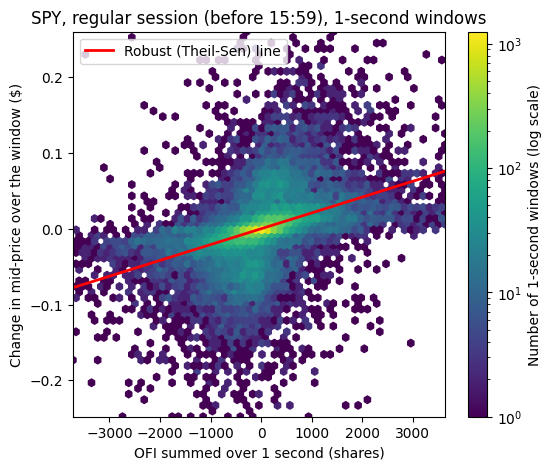

In [19]:
lx, hx = np.percentile(x2, [0.5, 99.5]); ly, hy = np.percentile(y2, [0.5, 99.5])
print("share outside plot box:", ((x2 < lx) | (x2 > hx) | (y2 < ly) | (y2 > hy)).mean())

fig, ax = plt.subplots(figsize=(6, 5))
hb = ax.hexbin(x2, y2, gridsize=60, bins="log", extent=(lx, hx, ly, hy), mincnt=1)
fig.colorbar(hb, label="Number of 1-second windows (log scale)")
xs = np.array([lx, hx])
ax.plot(xs, s2 * xs + i2, color="red", lw=2, label="Robust (Theil-Sen) line")
ax.set_xlim(lx, hx); ax.set_ylim(ly, hy)
ax.set_xlabel("OFI summed over 1 second (shares)")
ax.set_ylabel("Change in mid-price over the window ($)")
ax.set_title("SPY, regular session (before 15:59), 1-second windows")
ax.legend(loc="upper left")
fig.savefig(ROOT / "figures" / "02_spy_ofi_vs_dmid_1s.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
#residual plot

residual percentiles [1, 25, 50, 75, 99]: [-0.16449239 -0.01076642  0.          0.01085075  0.16120382]


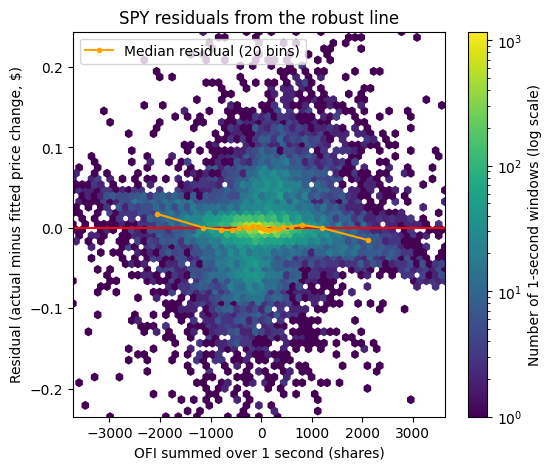

In [21]:
resid = y2 - (s2 * x2 + i2)
print("residual percentiles [1, 25, 50, 75, 99]:", np.percentile(resid, [1, 25, 50, 75, 99]))

lr, hr = np.percentile(resid, [0.5, 99.5])
fig, ax = plt.subplots(figsize=(6, 5))
hb = ax.hexbin(x2, resid, gridsize=60, bins="log", extent=(lx, hx, lr, hr), mincnt=1)
fig.colorbar(hb, label="Number of 1-second windows (log scale)")
ax.axhline(0, color="red", lw=1.5)

edges = np.quantile(x2, np.linspace(0, 1, 21))
b = np.digitize(x2, edges[1:-1])
ks = [k for k in range(20) if (b == k).any()]
ax.plot([np.median(x2[b == k]) for k in ks], [np.median(resid[b == k]) for k in ks],
        color="orange", marker="o", ms=3, label="Median residual (20 bins)")

ax.set_xlim(lx, hx); ax.set_ylim(lr, hr)
ax.set_xlabel("OFI summed over 1 second (shares)")
ax.set_ylabel("Residual (actual minus fitted price change, $)")
ax.set_title("SPY residuals from the robust line")
ax.legend(loc="upper left")
fig.savefig(ROOT / "figures" / "03_spy_ofi_residuals_1s.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
from scipy.stats import theilslopes, spearmanr

def window_fit(sym, every, n=5000, seed=42):
    d = (book.filter((pl.col("symbol") == sym) & (pl.col("session") == "regular"))
             .sort("timestamp")
             .group_by_dynamic("timestamp", every=every)
             .agg(pl.col("ofi").sum().alias("ofi_sum"), pl.col("mid").last().alias("mid_end"))
             .with_columns(pl.col("mid_end").diff().alias("dmid_w"))
             .drop_nulls(["ofi_sum", "dmid_w"]))
    ny = pl.col("timestamp").dt.convert_time_zone("America/New_York")
    d = d.filter((ny.dt.hour() < 15) | ((ny.dt.hour() == 15) & (ny.dt.minute() < 59)))
    x, y = d["ofi_sum"].to_numpy(), d["dmid_w"].to_numpy()
    idx = np.random.default_rng(seed).choice(len(x), size=min(n, len(x)), replace=False)
    s, i, lo, hi = theilslopes(y[idx], x[idx])
    return dict(symbol=sym, window=every, n_windows=len(x),
                spearman=round(float(spearmanr(x, y)[0]), 3),
                slope=s, slope_lo=lo, slope_hi=hi)

rows = [window_fit(s, e) for s in ["SPY", "QQQ", "IWM", "EMB", "VCSH"] for e in ["1s", "10s", "1m"]]
pl.Config.set_tbl_rows(20); pl.Config.set_tbl_cols(10)
print(pl.DataFrame(rows))

shape: (15, 7)
┌────────┬────────┬───────────┬──────────┬───────────┬──────────┬──────────┐
│ symbol ┆ window ┆ n_windows ┆ spearman ┆ slope     ┆ slope_lo ┆ slope_hi │
│ ---    ┆ ---    ┆ ---       ┆ ---      ┆ ---       ┆ ---      ┆ ---      │
│ str    ┆ str    ┆ i64       ┆ f64      ┆ f64       ┆ f64      ┆ f64      │
╞════════╪════════╪═══════════╪══════════╪═══════════╪══════════╪══════════╡
│ SPY    ┆ 1s     ┆ 23280     ┆ 0.592    ┆ 0.000021  ┆ 0.00002  ┆ 0.000022 │
│ SPY    ┆ 10s    ┆ 2333      ┆ 0.539    ┆ 0.000013  ┆ 0.000012 ┆ 0.000014 │
│ SPY    ┆ 1m     ┆ 388       ┆ 0.447    ┆ 0.000008  ┆ 0.000007 ┆ 0.00001  │
│ QQQ    ┆ 1s     ┆ 23338     ┆ 0.527    ┆ 0.000015  ┆ 0.000014 ┆ 0.000016 │
│ QQQ    ┆ 10s    ┆ 2333      ┆ 0.336    ┆ 0.000006  ┆ 0.000006 ┆ 0.000007 │
│ QQQ    ┆ 1m     ┆ 388       ┆ 0.085    ┆ 9.1262e-7 ┆ 0.0      ┆ 0.000002 │
│ IWM    ┆ 1s     ┆ 23132     ┆ 0.843    ┆ 0.000004  ┆ 0.000003 ┆ 0.000004 │
│ IWM    ┆ 10s    ┆ 2333      ┆ 0.823    ┆ 0.000004  ┆ 0.0000

In [23]:
from scipy.stats import theilslopes, spearmanr

def window_fit(sym, every, n=5000, seed=42):
    d = (book.filter((pl.col("symbol") == sym) & (pl.col("session") == "regular"))
             .sort("timestamp")
             .group_by_dynamic("timestamp", every=every)
             .agg(pl.col("ofi").sum().alias("ofi_sum"), pl.col("mid").last().alias("mid_end"))
             .with_columns(pl.col("mid_end").diff().alias("dmid_w"))
             .drop_nulls(["ofi_sum", "dmid_w"]))
    ny = pl.col("timestamp").dt.convert_time_zone("America/New_York")
    d = d.filter((ny.dt.hour() < 15) | ((ny.dt.hour() == 15) & (ny.dt.minute() < 59)))
    x, y = d["ofi_sum"].to_numpy(), d["dmid_w"].to_numpy()
    idx = np.random.default_rng(seed).choice(len(x), size=min(n, len(x)), replace=False)
    s, i, lo, hi = theilslopes(y[idx], x[idx])
    return dict(symbol=sym, window=every, n_windows=len(x),
                spearman=round(float(spearmanr(x, y)[0]), 3),
                share_dmid_zero=round(float((y == 0).mean()), 3),
                cents_per_1000_shares=round(s * 1000 * 100, 4),
                lo=round(lo * 1000 * 100, 4), hi=round(hi * 1000 * 100, 4))

rows = [window_fit(s, e) for s in ["SPY", "QQQ", "IWM", "EMB", "VCSH"] for e in ["1s", "10s", "1m"]]
pl.Config.set_tbl_rows(20); pl.Config.set_tbl_cols(10)
print(pl.DataFrame(rows))

shape: (15, 8)
┌────────┬────────┬───────────┬──────────┬─────────────────┬─────────────────────┬────────┬────────┐
│ symbol ┆ window ┆ n_windows ┆ spearman ┆ share_dmid_zero ┆ cents_per_1000_shar ┆ lo     ┆ hi     │
│ ---    ┆ ---    ┆ ---       ┆ ---      ┆ ---             ┆ es                  ┆ ---    ┆ ---    │
│ str    ┆ str    ┆ i64       ┆ f64      ┆ f64             ┆ ---                 ┆ f64    ┆ f64    │
│        ┆        ┆           ┆          ┆                 ┆ f64                 ┆        ┆        │
╞════════╪════════╪═══════════╪══════════╪═════════════════╪═════════════════════╪════════╪════════╡
│ SPY    ┆ 1s     ┆ 23280     ┆ 0.592    ┆ 0.184           ┆ 2.0896              ┆ 1.9973 ┆ 2.1898 │
│ SPY    ┆ 10s    ┆ 2333      ┆ 0.539    ┆ 0.041           ┆ 1.3253              ┆ 1.2337 ┆ 1.4188 │
│ SPY    ┆ 1m     ┆ 388       ┆ 0.447    ┆ 0.01            ┆ 0.8376              ┆ 0.6739 ┆ 1.0055 │
│ QQQ    ┆ 1s     ┆ 23338     ┆ 0.527    ┆ 0.127           ┆ 1.4925         

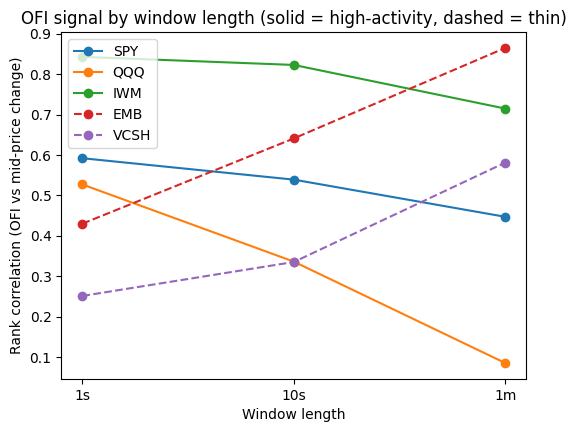

In [24]:
res = pl.DataFrame(rows)
order = ["1s", "10s", "1m"]
fig, ax = plt.subplots(figsize=(6, 4.5))
for sym in ["SPY", "QQQ", "IWM", "EMB", "VCSH"]:
    d = res.filter(pl.col("symbol") == sym)
    vals = [d.filter(pl.col("window") == o)["spearman"].item() for o in order]
    ax.plot(order, vals, marker="o", label=sym, ls="-" if sym in ("SPY", "QQQ", "IWM") else "--")
ax.set_xlabel("Window length")
ax.set_ylabel("Rank correlation (OFI vs mid-price change)")
ax.set_title("OFI signal by window length (solid = high-activity, dashed = thin)")
ax.legend()
fig.savefig(ROOT / "figures" / "04_spearman_by_window.png", dpi=150, bbox_inches="tight")
plt.show()

In [25]:
print(trades.columns)

b = (book.sort("timestamp")
         .with_columns(pl.col("ofi").fill_null(0).cum_sum().over("symbol").alias("cum_ofi"))
         .select("symbol", "timestamp", "cum_ofi", "mid"))
b_start = b.select("symbol", pl.col("timestamp").alias("ts_b"), pl.col("cum_ofi").alias("cum_start"))

t = (trades.filter(pl.col("usable_trade"))
           .select("symbol", "timestamp", "price")
           .sort("timestamp")
           .with_columns((pl.col("timestamp") - pl.duration(seconds=1)).alias("t_start")))

d = (t.join_asof(b, on="timestamp", by="symbol", strategy="backward", allow_exact_matches=False)
      .rename({"cum_ofi": "cum_end", "mid": "mid_before"})
      .join_asof(b_start, left_on="t_start", right_on="ts_b", by="symbol", strategy="backward")
      .with_columns((pl.col("cum_end") - pl.col("cum_start")).alias("ofi_prior"),
                    (pl.col("price") - pl.col("mid_before")).round(4).sign().alias("dir"))
      .drop_nulls(["ofi_prior", "dir"]))

n_usable = t.group_by("symbol").len().rename({"len": "n_usable"})
sc = (d.filter(pl.col("dir") != 0)
        .with_columns((pl.col("ofi_prior").sign() == pl.col("dir")).alias("hit"))
        .group_by("symbol")
        .agg(pl.len().alias("n_classified"),
             (pl.col("dir") > 0).mean().alias("share_buys"),
             (pl.col("ofi_prior") == 0).mean().alias("share_ofi_zero"),
             pl.col("hit").filter(pl.col("ofi_prior") != 0).mean().alias("hit_rate"),
             pl.col("hit").filter(pl.col("ofi_prior") != 0).len().alias("n_scored")))

res2 = (n_usable.join(sc, on="symbol")
        .with_columns(pl.max_horizontal(pl.col("share_buys"), 1 - pl.col("share_buys")).alias("baseline"),
                      (1.96 * (pl.col("hit_rate") * (1 - pl.col("hit_rate")) / pl.col("n_scored")).sqrt()).alias("margin_95"))
        .with_columns(pl.col(pl.Float64).round(3)))
pl.Config.set_tbl_cols(12)
print(res2)

['timestamp', 'symbol', 'type', 'side', 'price', 'size', 'flags', 'trade_id', 'session', 'usable_trade']


/var/folders/fh/7rjlb53n6kx8__xwl25t8ys00000gn/T/ipykernel_82655/461812264.py:13: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided
  d = (t.join_asof(b, on="timestamp", by="symbol", strategy="backward", allow_exact_matches=False)


shape: (5, 9)
┌────────┬──────────┬───────────┬───────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
│ symbol ┆ n_usable ┆ n_classif ┆ share_buy ┆ share_of ┆ hit_rate ┆ n_scored ┆ baseline ┆ margin_9 │
│ ---    ┆ ---      ┆ ied       ┆ s         ┆ i_zero   ┆ ---      ┆ ---      ┆ ---      ┆ 5        │
│ str    ┆ u32      ┆ ---       ┆ ---       ┆ ---      ┆ f64      ┆ u32      ┆ f64      ┆ ---      │
│        ┆          ┆ u32       ┆ f64       ┆ f64      ┆          ┆          ┆          ┆ f64      │
╞════════╪══════════╪═══════════╪═══════════╪══════════╪══════════╪══════════╪══════════╪══════════╡
│ IWM    ┆ 7963     ┆ 6392      ┆ 0.444     ┆ 0.011    ┆ 0.497    ┆ 6323     ┆ 0.556    ┆ 0.012    │
│ SPY    ┆ 12139    ┆ 10158     ┆ 0.526     ┆ 0.009    ┆ 0.446    ┆ 10065    ┆ 0.526    ┆ 0.01     │
│ QQQ    ┆ 4564     ┆ 4109      ┆ 0.404     ┆ 0.007    ┆ 0.487    ┆ 4080     ┆ 0.596    ┆ 0.015    │
│ VCSH   ┆ 409      ┆ 220       ┆ 0.405     ┆ 0.477    ┆ 0.565    ┆ 115      

In [26]:
# Part A: do buy-labelled trades get followed by a higher mid? (label sanity check)
after = (d.select("symbol", "timestamp", "dir", "mid_before")
          .with_columns((pl.col("timestamp") + pl.duration(seconds=1)).alias("t_after"))
          .sort("t_after")
          .join_asof(b.select("symbol", pl.col("timestamp").alias("t_after"), pl.col("mid").alias("mid_after")),
                     on="t_after", by="symbol", strategy="backward")
          .with_columns((pl.col("mid_after") - pl.col("mid_before")).alias("dmid_after")))
print(after.filter(pl.col("dir") != 0)
           .group_by("symbol", "dir")
           .agg(pl.col("dmid_after").mean().round(4).alias("avg_mid_change_next_1s"), pl.len())
           .sort("symbol", "dir"))

# Part B: does the hit rate change if we look only at the last few milliseconds before the trade?
def hits(ms):
    t2 = t.with_columns((pl.col("timestamp") - pl.duration(milliseconds=ms)).alias("t_start"))
    d2 = (t2.join_asof(b, on="timestamp", by="symbol", strategy="backward", allow_exact_matches=False)
            .rename({"cum_ofi": "cum_end", "mid": "mid_before"})
            .join_asof(b_start, left_on="t_start", right_on="ts_b", by="symbol", strategy="backward")
            .with_columns((pl.col("cum_end") - pl.col("cum_start")).alias("ofi_prior"),
                          (pl.col("price") - pl.col("mid_before")).round(4).sign().alias("dir"))
            .drop_nulls(["ofi_prior", "dir"])
            .filter((pl.col("dir") != 0) & (pl.col("ofi_prior") != 0)))
    return (d2.group_by("symbol")
              .agg((pl.col("ofi_prior").sign() == pl.col("dir")).mean().round(3).alias(f"hit_{ms}ms"),
                   pl.len().alias(f"n_{ms}ms")))

out = hits(1000)
for ms in [100, 10, 1]:
    out = out.join(hits(ms), on="symbol")
print(out.sort("symbol"))

/var/folders/fh/7rjlb53n6kx8__xwl25t8ys00000gn/T/ipykernel_82655/1883124219.py:2: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided
  after = (d.select("symbol", "timestamp", "dir", "mid_before")


shape: (10, 4)
┌────────┬──────┬────────────────────────┬──────┐
│ symbol ┆ dir  ┆ avg_mid_change_next_1s ┆ len  │
│ ---    ┆ ---  ┆ ---                    ┆ ---  │
│ str    ┆ f64  ┆ f64                    ┆ u32  │
╞════════╪══════╪════════════════════════╪══════╡
│ EMB    ┆ -1.0 ┆ -0.0033                ┆ 337  │
│ EMB    ┆ 1.0  ┆ 0.0054                 ┆ 380  │
│ IWM    ┆ -1.0 ┆ 0.0011                 ┆ 3554 │
│ IWM    ┆ 1.0  ┆ 0.0159                 ┆ 2838 │
│ QQQ    ┆ -1.0 ┆ -0.0142                ┆ 2447 │
│ QQQ    ┆ 1.0  ┆ 0.0265                 ┆ 1662 │
│ SPY    ┆ -1.0 ┆ -0.0225                ┆ 4817 │
│ SPY    ┆ 1.0  ┆ 0.0176                 ┆ 5341 │
│ VCSH   ┆ -1.0 ┆ 0.0178                 ┆ 131  │
│ VCSH   ┆ 1.0  ┆ 0.1498                 ┆ 89   │
└────────┴──────┴────────────────────────┴──────┘


/var/folders/fh/7rjlb53n6kx8__xwl25t8ys00000gn/T/ipykernel_82655/1883124219.py:16: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided
  d2 = (t2.join_asof(b, on="timestamp", by="symbol", strategy="backward", allow_exact_matches=False)


shape: (5, 9)
┌────────┬────────────┬──────────┬───────────┬─────────┬──────────┬────────┬─────────┬───────┐
│ symbol ┆ hit_1000ms ┆ n_1000ms ┆ hit_100ms ┆ n_100ms ┆ hit_10ms ┆ n_10ms ┆ hit_1ms ┆ n_1ms │
│ ---    ┆ ---        ┆ ---      ┆ ---       ┆ ---     ┆ ---      ┆ ---    ┆ ---     ┆ ---   │
│ str    ┆ f64        ┆ u32      ┆ f64       ┆ u32     ┆ f64      ┆ u32    ┆ f64     ┆ u32   │
╞════════╪════════════╪══════════╪═══════════╪═════════╪══════════╪════════╪═════════╪═══════╡
│ EMB    ┆ 0.603      ┆ 464      ┆ 0.716     ┆ 282     ┆ 0.78     ┆ 209    ┆ 0.804   ┆ 138   │
│ IWM    ┆ 0.497      ┆ 6323     ┆ 0.497     ┆ 5675    ┆ 0.569    ┆ 4004   ┆ 0.618   ┆ 2248  │
│ QQQ    ┆ 0.487      ┆ 4080     ┆ 0.459     ┆ 3705    ┆ 0.466    ┆ 2398   ┆ 0.507   ┆ 1233  │
│ SPY    ┆ 0.446      ┆ 10065    ┆ 0.458     ┆ 8839    ┆ 0.503    ┆ 6045   ┆ 0.557   ┆ 3442  │
│ VCSH   ┆ 0.565      ┆ 115      ┆ 0.584     ┆ 89      ┆ 0.603    ┆ 73     ┆ 0.364   ┆ 44    │
└────────┴────────────┴──────────┴──

In [27]:
def gap_hit(gap_ms):
    g = (d.select("symbol", "timestamp", "dir", "cum_start")
          .with_columns((pl.col("timestamp") - pl.duration(milliseconds=gap_ms)).alias("t_end"))
          .sort("t_end")
          .join_asof(b.select("symbol", pl.col("timestamp").alias("t_end"), pl.col("cum_ofi").alias("cum_gap")),
                     on="t_end", by="symbol", strategy="backward")
          .with_columns((pl.col("cum_gap") - pl.col("cum_start")).alias("ofi_gap"))
          .filter((pl.col("dir") != 0) & (pl.col("ofi_gap") != 0)))
    return (g.group_by("symbol")
             .agg((pl.col("ofi_gap").sign() == pl.col("dir")).mean().round(3).alias(f"hit_gap{gap_ms}ms"),
                  pl.len().alias(f"n_gap{gap_ms}ms")))

out2 = gap_hit(10)
for gm in [100, 500]:
    out2 = out2.join(gap_hit(gm), on="symbol")
print(out2.sort("symbol"))

/var/folders/fh/7rjlb53n6kx8__xwl25t8ys00000gn/T/ipykernel_82655/1463927275.py:2: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided
  g = (d.select("symbol", "timestamp", "dir", "cum_start")


shape: (5, 7)
┌────────┬─────────────┬───────────┬──────────────┬────────────┬──────────────┬────────────┐
│ symbol ┆ hit_gap10ms ┆ n_gap10ms ┆ hit_gap100ms ┆ n_gap100ms ┆ hit_gap500ms ┆ n_gap500ms │
│ ---    ┆ ---         ┆ ---       ┆ ---          ┆ ---        ┆ ---          ┆ ---        │
│ str    ┆ f64         ┆ u32       ┆ f64          ┆ u32        ┆ f64          ┆ u32        │
╞════════╪═════════════╪═══════════╪══════════════╪════════════╪══════════════╪════════════╡
│ EMB    ┆ 0.525       ┆ 400       ┆ 0.517        ┆ 360        ┆ 0.475        ┆ 278        │
│ IWM    ┆ 0.487       ┆ 6292      ┆ 0.481        ┆ 6224       ┆ 0.508        ┆ 5920       │
│ QQQ    ┆ 0.491       ┆ 4069      ┆ 0.493        ┆ 4062       ┆ 0.51         ┆ 3980       │
│ SPY    ┆ 0.448       ┆ 10048     ┆ 0.473        ┆ 9976       ┆ 0.496        ┆ 9679       │
│ VCSH   ┆ 0.558       ┆ 77        ┆ 0.558        ┆ 77         ┆ 0.487        ┆ 39         │
└────────┴─────────────┴───────────┴──────────────┴─────

shape: (15, 5)
┌────────┬─────────┬─────────┬────────┬──────────────────┐
│ symbol ┆ session ┆ quotes  ┆ trades ┆ quotes_per_trade │
│ ---    ┆ ---     ┆ ---     ┆ ---    ┆ ---              │
│ str    ┆ str     ┆ u32     ┆ u32    ┆ f64              │
╞════════╪═════════╪═════════╪════════╪══════════════════╡
│ EMB    ┆ after   ┆ 3       ┆ null   ┆ null             │
│ EMB    ┆ pre     ┆ 352     ┆ null   ┆ null             │
│ EMB    ┆ regular ┆ 92818   ┆ 1661   ┆ 55.9             │
│ IWM    ┆ after   ┆ 1633    ┆ 23     ┆ 71.0             │
│ IWM    ┆ pre     ┆ 180     ┆ 13     ┆ 13.8             │
│ IWM    ┆ regular ┆ 1973381 ┆ 10358  ┆ 190.5            │
│ QQQ    ┆ after   ┆ 17157   ┆ 48     ┆ 357.4            │
│ QQQ    ┆ pre     ┆ 60799   ┆ 98     ┆ 620.4            │
│ QQQ    ┆ regular ┆ 3010264 ┆ 7548   ┆ 398.8            │
│ SPY    ┆ after   ┆ 2422    ┆ 26     ┆ 93.2             │
│ SPY    ┆ pre     ┆ 23606   ┆ 66     ┆ 357.7            │
│ SPY    ┆ regular ┆ 2236684 ┆ 18779  ┆ 1

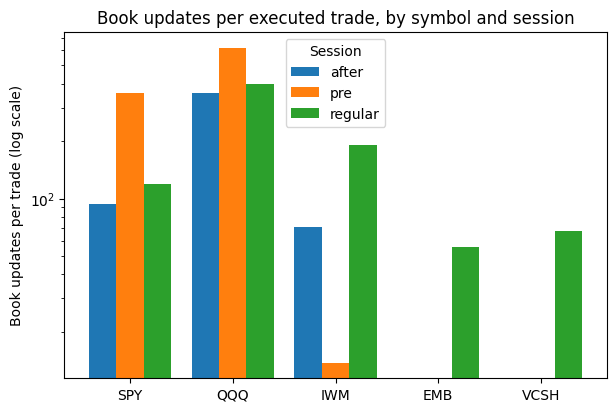

In [28]:
q = book.group_by("symbol", "session").agg(pl.len().alias("quotes"))
tr = trades.group_by("symbol", "session").agg(pl.len().alias("trades"))
qt = (q.join(tr, on=["symbol", "session"], how="left")
        .with_columns((pl.col("quotes") / pl.col("trades")).round(1).alias("quotes_per_trade")))
print(qt.sort("symbol", "session"))

syms = ["SPY", "QQQ", "IWM", "EMB", "VCSH"]
sess = qt["session"].unique().sort().to_list()
bw = 0.8 / len(sess)
fig, ax = plt.subplots(figsize=(7, 4.5))
for j, s in enumerate(sess):
    vals = []
    for sym in syms:
        r = qt.filter((pl.col("symbol") == sym) & (pl.col("session") == s))["quotes_per_trade"]
        vals.append(r.item() if len(r) and r.item() is not None else float("nan"))
    ax.bar(np.arange(len(syms)) + j * bw, vals, width=bw, label=s)
ax.set_xticks(np.arange(len(syms)) + bw * (len(sess) - 1) / 2)
ax.set_xticklabels(syms)
ax.set_yscale("log")
ax.set_ylabel("Book updates per trade (log scale)")
ax.set_title("Book updates per executed trade, by symbol and session")
ax.legend(title="Session")
fig.savefig(ROOT / "figures" / "05_quotes_per_trade.png", dpi=150, bbox_inches="tight")
plt.show()

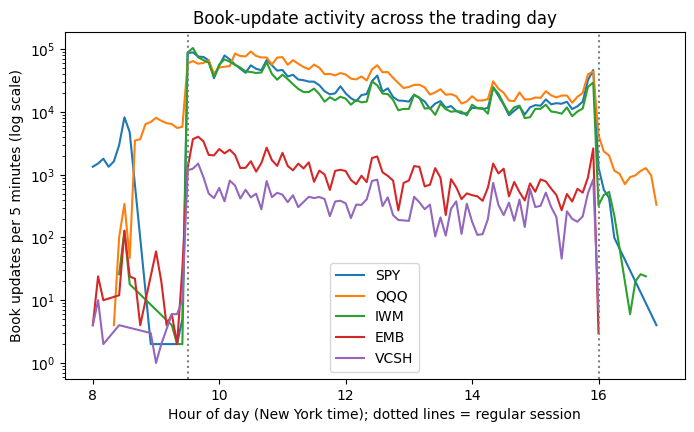

In [29]:
ny = pl.col("timestamp").dt.convert_time_zone("America/New_York")
act = (book.with_columns((ny.dt.hour() + (ny.dt.minute() // 5) * 5 / 60).alias("hr"))
           .group_by("symbol", "hr").agg(pl.len().alias("n")).sort("hr"))

fig, ax = plt.subplots(figsize=(8, 4.5))
for sym in syms:
    dd = act.filter(pl.col("symbol") == sym)
    ax.plot(dd["hr"], dd["n"], label=sym)
ax.set_yscale("log")
ax.axvline(9.5, color="gray", ls=":"); ax.axvline(16, color="gray", ls=":")
ax.set_xlabel("Hour of day (New York time); dotted lines = regular session")
ax.set_ylabel("Book updates per 5 minutes (log scale)")
ax.set_title("Book-update activity across the trading day")
ax.legend()
fig.savefig(ROOT / "figures" / "06_activity_by_time.png", dpi=150, bbox_inches="tight")
plt.show()

shape: (5, 3)
┌────────┬───────┬──────────────────┐
│ symbol ┆ secs  ┆ share_of_seconds │
│ ---    ┆ ---   ┆ ---              │
│ str    ┆ u32   ┆ f64              │
╞════════╪═══════╪══════════════════╡
│ EMB    ┆ 12514 ┆ 0.535            │
│ IWM    ┆ 23193 ┆ 0.991            │
│ QQQ    ┆ 23399 ┆ 1.0              │
│ SPY    ┆ 23341 ┆ 0.997            │
│ VCSH   ┆ 6899  ┆ 0.295            │
└────────┴───────┴──────────────────┘


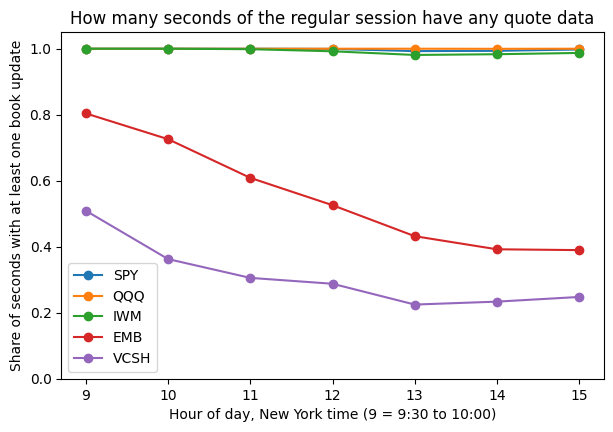

In [30]:
reg = (book.filter(pl.col("session") == "regular")
           .with_columns(pl.col("timestamp").dt.truncate("1s").alias("sec"),
                         pl.col("timestamp").dt.convert_time_zone("America/New_York").dt.hour().alias("hour")))

print(reg.group_by("symbol").agg(pl.col("sec").n_unique().alias("secs"))
         .with_columns((pl.col("secs") / 23400).round(3).alias("share_of_seconds"))
         .sort("symbol"))

cov = (reg.group_by("symbol", "hour").agg(pl.col("sec").n_unique().alias("secs"))
          .with_columns((pl.col("secs") / pl.when(pl.col("hour") == 9).then(1800).otherwise(3600)).alias("share"))
          .sort("symbol", "hour"))

fig, ax = plt.subplots(figsize=(7, 4.5))
for sym in syms:
    dd = cov.filter(pl.col("symbol") == sym)
    ax.plot(dd["hour"], dd["share"], marker="o", label=sym)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Hour of day, New York time (9 = 9:30 to 10:00)")
ax.set_ylabel("Share of seconds with at least one book update")
ax.set_title("How many seconds of the regular session have any quote data")
ax.legend()
fig.savefig(ROOT / "figures" / "07_second_coverage.png", dpi=150, bbox_inches="tight")
plt.show()

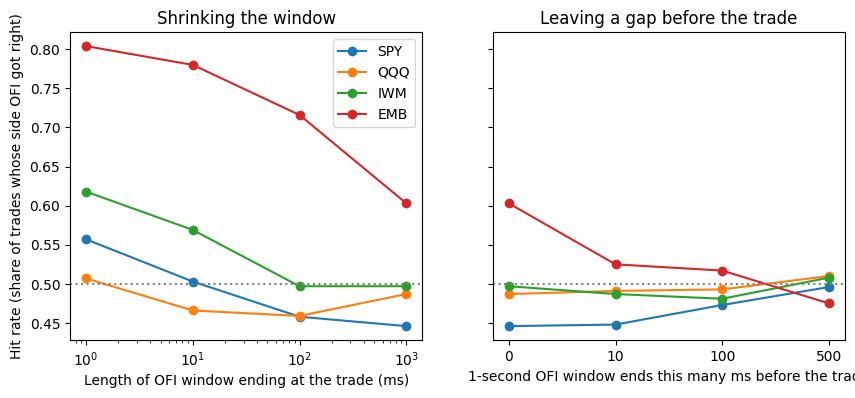

In [31]:
show = ["SPY", "QQQ", "IWM", "EMB"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for sym in show:
    r = out.filter(pl.col("symbol") == sym)
    r2 = out2.filter(pl.col("symbol") == sym)
    lens = [1, 10, 100, 1000]
    a1.plot(lens, [r[f"hit_{m}ms"].item() for m in lens], marker="o", label=sym)
    vals = [r["hit_1000ms"].item()] + [r2[f"hit_gap{g}ms"].item() for g in [10, 100, 500]]
    a2.plot(range(4), vals, marker="o", label=sym)
for a in (a1, a2):
    a.axhline(0.5, color="gray", ls=":")
a1.set_xscale("log")
a1.set_xlabel("Length of OFI window ending at the trade (ms)")
a2.set_xticks(range(4)); a2.set_xticklabels(["0", "10", "100", "500"])
a2.set_xlabel("1-second OFI window ends this many ms before the trade")
a1.set_ylabel("Hit rate (share of trades whose side OFI got right)")
a1.set_title("Shrinking the window"); a2.set_title("Leaving a gap before the trade")
a1.legend()
fig.savefig(ROOT / "figures" / "08_hit_rate_by_gap.png", dpi=150, bbox_inches="tight")
plt.show()